# SingleAgent Debug Analysis 2

This notebook uses the **theoretical Q-value formulas from `basin.py`** (QvaluesADvsAD, QvaluesGTvsGT, etc.)
instead of the original `Theoretical_QValueCalculator` from `SingleAgent_ExpSarsa.py`.

## Key difference:
- **basin.py formulas**: Derived from the closed-form solutions for Q-values when playing against specific opponent strategies
- Maps: `QvaluesADvsAD` (AllD vs AllD), `QvaluesGTvsGT` (GT vs GT), `QvaluesADvsAGT` (AllD vs AGT), `QvaluesADvsAC` (AllD vs AC)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent_ExpSarsa import *
import sys
sys.path.append('../')
sys.path.append('../MultiAgent/')
from utils import *
from basin import QvaluesADvsAD, QvaluesGTvsGT, QvaluesADvsAGT, QvaluesADvsAC

## Theoretical Q-Value Calculator using basin.py formulas

The `basin.py` functions return Q-values in format:
```
[[Q_defect_state0, Q_coop_state0],
 [Q_defect_state1, Q_coop_state1]]
```

We adapt this to the SingleAgent convention:
- Q00 = cooperate action in state 0
- Q01 = cooperate action in state 1  
- Q10 = defect action in state 0
- Q11 = defect action in state 1

In [2]:
class Theoretical_QValueCalculator_Basin:
    """
    Theoretical Q-Value Calculator using closed-form formulas from basin.py.
    
    Uses the exact Q-value solutions derived for different strategy matchups:
    - QvaluesADvsAD: Q-values when playing AllD vs opponent playing AllD
    - QvaluesGTvsGT: Q-values when playing GT vs opponent playing GT  
    - QvaluesADvsAGT: Q-values when playing AllD vs opponent playing AGT
    - QvaluesADvsAC: Q-values when playing AllD vs opponent playing AllC
    """
    
    def __init__(self, epsilon, P, R, T, S, delta):
        """
        Initialize with game parameters.
        
        Parameters:
            epsilon: Exploration parameter
            P: Punishment (both defect)
            R: Reward (both cooperate)  
            T: Temptation (defect vs cooperate)
            S: Sucker's payoff (cooperate vs defect)
            delta: Discount factor
        """
        self.epsilon = epsilon
        self.P = P
        self.R = R
        self.T = T
        self.S = S
        self.delta = delta
        # Map to basin.py naming convention: t=T, r=R, p=P, s=S
        self.t = T
        self.r = R
        self.p = P
        self.s = S
    
    def _basin_to_single_agent(self, q_basin):
        """
        Convert basin.py Q-value format to SingleAgent format.
        
        basin.py: [[Q_defect_s0, Q_coop_s0], [Q_defect_s1, Q_coop_s1]]
        SingleAgent: Q00 (coop,s0), Q01 (coop,s1), Q10 (defect,s0), Q11 (defect,s1)
        """
        Q00 = q_basin[0, 1]  # cooperate in state 0
        Q01 = q_basin[1, 1]  # cooperate in state 1
        Q10 = q_basin[0, 0]  # defect in state 0
        Q11 = q_basin[1, 0]  # defect in state 1
        return Q00, Q01, Q10, Q11
    
    def calculate_c1_c2(self):
        """
        Calculate critical delta thresholds c1 and c2.
        c1: threshold below which AllD is optimal
        c2: threshold above which AllC is optimal
        Between c1 and c2: GrimTrigger is optimal
        """
        P, R, T, S = self.P, self.R, self.T, self.S
        epsilon_value = self.epsilon
        
        c2 = ((2*P) - (epsilon_value*P) - (epsilon_value*R) - (2*S) + (epsilon_value*S) + (epsilon_value*T)) / \
             ((-1 + epsilon_value) * ((-2*P) + (2*epsilon_value*P) + (2*S) - (epsilon_value*S) - (epsilon_value*T)))
        c1 = (-epsilon_value*P + 2*R - epsilon_value*R + epsilon_value*S - 2*T + epsilon_value*T) / \
             ((-1 + epsilon_value) * (-2*P + 2*epsilon_value*P - epsilon_value*S + 2*T - epsilon_value*T))
        
        return c1, c2
    
    def calculate_q_values_eGT(self):
        """Q-values for epsilon-GrimTrigger (GT vs GT) using basin.py formula."""
        q_basin = QvaluesGTvsGT(self.t, self.r, self.p, self.s, self.epsilon, self.delta)
        return self._basin_to_single_agent(q_basin)
    
    def calculate_q_values_eAD(self):
        """Q-values for epsilon-AllDefect (AD vs AD) using basin.py formula."""
        q_basin = QvaluesADvsAD(self.t, self.r, self.p, self.s, self.epsilon, self.delta)
        return self._basin_to_single_agent(q_basin)
    
    def calculate_q_values_eAC(self):
        """Q-values for epsilon-AllCooperate (using iterative method as in original)."""
        # Note: basin.py doesn't have QvaluesACvsAC, so we use the original iterative method
        Q00 = 0
        Q01 = 0
        tol = 1e-6
        for _ in range(100):
            Q01_new = ((1 - self.epsilon / 2) * self.S + (self.epsilon / 2) * self.R + 
                       (self.epsilon / 2) * self.delta * Q00) / (1 - (1 - self.epsilon / 2) * self.delta)
            Q00_new = ((1 - self.epsilon / 2) * self.R + (self.epsilon / 2) * self.S + 
                       (self.epsilon / 2) * self.delta * Q01_new) / (1 - (1 - self.epsilon / 2) * self.delta)
            if abs(Q01_new - Q01) < tol and abs(Q00_new - Q00) < tol:
                break
            Q00 = Q00_new
            Q01 = Q01_new
        Q11 = (1 - self.epsilon/2) * self.P + (self.epsilon/2 * self.T) + self.delta * Q01
        Q10 = ((1 - self.epsilon / 2) * self.T + (self.epsilon / 2) * self.P) + self.delta * Q01
        return Q00, Q01, Q10, Q11
    
    def calculate_q_values(self, c1, c2):
        """
        Calculate Q-values based on delta range using basin.py formulas.
        
        Returns:
            tuple: (Q00, Q01, Q10, Q11) - Q-values for each state-action pair
        """
        if self.delta < c1:
            print('Strategy is e-Always Defecting (using basin.py QvaluesADvsAD)')
            return self.calculate_q_values_eAD()
        elif c1 <= self.delta <= c2:
            print('Strategy is e-GrimTrigger (using basin.py QvaluesGTvsGT)')
            return self.calculate_q_values_eGT()
        else:
            print('Strategy is e-Always Cooperating (using iterative method)')
            return self.calculate_q_values_eAC()
    
    def print_strategy_chosen(self, c1, c2):
        if self.delta < c1:
            return 1  # e-Always Defecting
        elif c1 <= self.delta <= c2:
            return 2  # e-GrimTrigger
        else:
            return 3  # e-Always Cooperating
    
    def get_all_q_values_comparison(self):
        """
        Get Q-values for all strategies for comparison.
        
        Returns:
            dict: Q-values for AD, GT, and AC strategies
        """
        return {
            'AD': self.calculate_q_values_eAD(),
            'GT': self.calculate_q_values_eGT(),
            'AC': self.calculate_q_values_eAC()
        }

## Parameters Setup

In [3]:
# Game parameters
delta_value = 0.6
epsilon_value = 0.1
lambda_value = 0
P, R, T, S = 0.2, 0.8, 1, 0

print(f"Parameters: delta={delta_value}, epsilon={epsilon_value}, lambda={lambda_value}")
print(f"Payoffs: T={T}, R={R}, P={P}, S={S}")

Parameters: delta=0.6, epsilon=0.1, lambda=0
Payoffs: T=1, R=0.8, P=0.2, S=0


## Calculate Critical Deltas

In [4]:
# Calculate critical deltas using basin.py calculator
calculator_basin = Theoretical_QValueCalculator_Basin(
    epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=delta_value
)
c1, c2 = calculator_basin.calculate_c1_c2()
print(f'c1 = {round(c1, 4)}, c2 = {round(c2, 4)}')
print(f'delta = {delta_value}')
print(f'Strategy region: {"AD" if delta_value < c1 else "GT" if delta_value <= c2 else "AC"}')

c1 = 0.2886, c2 = 0.9662
delta = 0.6
Strategy region: GT


## Run Algorithm

In [5]:
strategy = epsilon_GrimTrigger()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=lambda_value,
    alpha=0.1,
    delta=delta_value,
    K=100,
    M=5,
    e_decay=1,
    random_uniform=False,
    verbose=False,
    plotting=False
)

In [6]:
# Run the solver
cooperations, defections, q1_history_per_sample, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
print(f"Cooperations: {cooperations}, Defections: {defections}")

Cooperations: 527, Defections: 38


## Calculate Theoretical Q-Values (using basin.py)

In [7]:
# Get theoretical Q-values using basin.py formulas
Q00, Q01, Q10, Q11 = calculator_basin.calculate_q_values(c1, c2)

print(f"\nTheoretical Q-values (from basin.py):")
print(f"  Q00 (cooperate, state 0) = {Q00:.6f}")
print(f"  Q01 (cooperate, state 1) = {Q01:.6f}")
print(f"  Q10 (defect, state 0)    = {Q10:.6f}")
print(f"  Q11 (defect, state 1)    = {Q11:.6f}")

Strategy is e-GrimTrigger (using basin.py QvaluesGTvsGT)

Theoretical Q-values (from basin.py):
  Q00 (cooperate, state 0) = 1.776772
  Q01 (cooperate, state 1) = 0.422859
  Q10 (defect, state 0)    = 1.307641
  Q11 (defect, state 1)    = 0.587641


## Compare with Original Calculator

In [8]:
# Compare with original calculator from SingleAgent_ExpSarsa.py
calculator_original = Theoretical_QValueCalculator(
    epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=delta_value
)
Q00_orig, Q01_orig, Q10_orig, Q11_orig = calculator_original.calculate_q_values(c1, c2)

print(f"\nOriginal Q-values (from SingleAgent_ExpSarsa.py):")
print(f"  Q00 (cooperate, state 0) = {Q00_orig:.6f}")
print(f"  Q01 (cooperate, state 1) = {Q01_orig:.6f}")
print(f"  Q10 (defect, state 0)    = {Q10_orig:.6f}")
print(f"  Q11 (defect, state 1)    = {Q11_orig:.6f}")

print(f"\nDifferences (basin - original):")
print(f"  dQ00 = {Q00 - Q00_orig:.6f}")
print(f"  dQ01 = {Q01 - Q01_orig:.6f}")
print(f"  dQ10 = {Q10 - Q10_orig:.6f}")
print(f"  dQ11 = {Q11 - Q11_orig:.6f}")

Strategy is e-GrimTrigger


TypeError: cannot unpack non-iterable NoneType object

## Plot Value Iteration with basin.py Theoretical Values

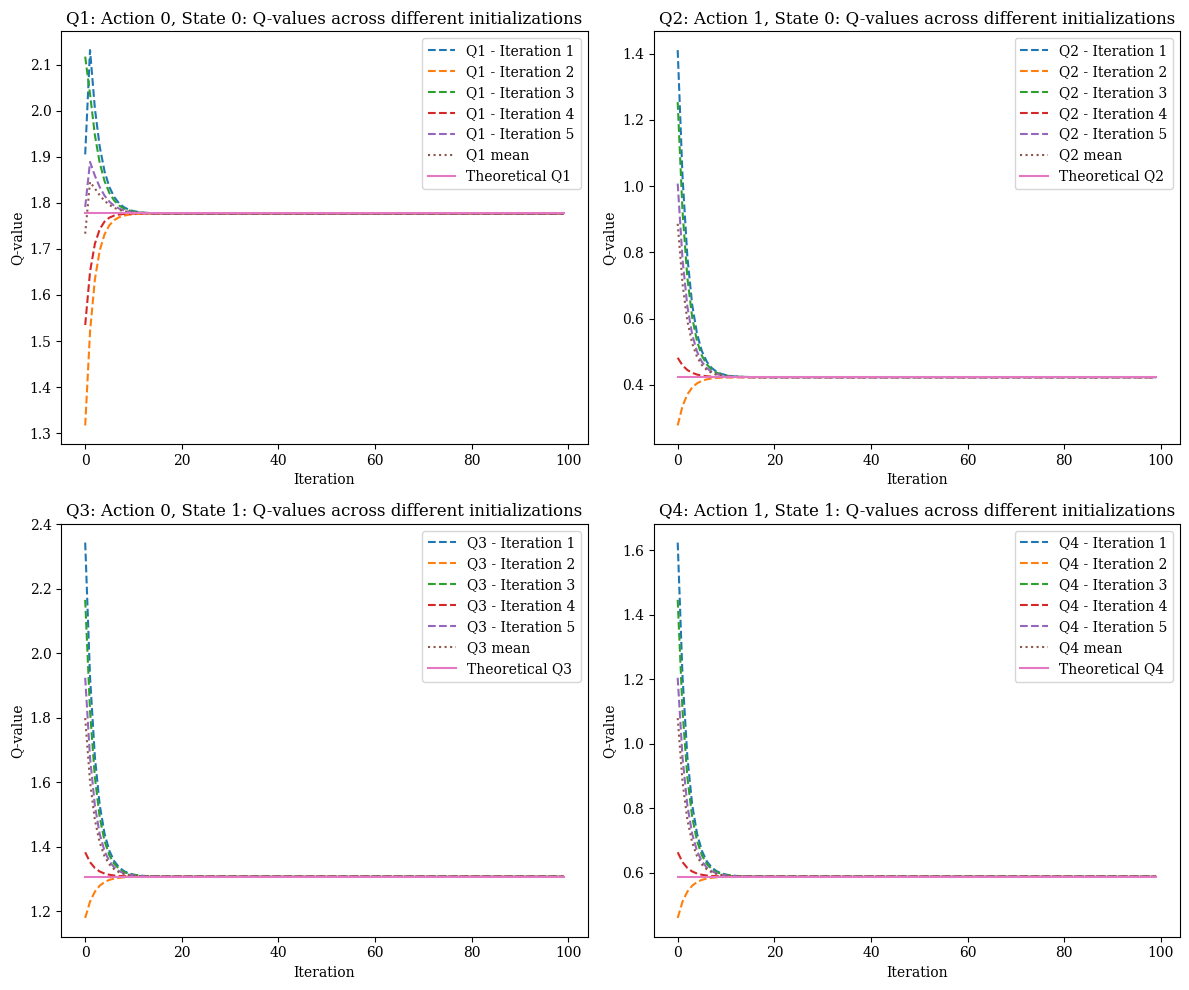

In [ ]:
# Plot value iteration with theoretical values from basin.py
solver.plot_value_iteration(Q00, Q01, Q10, Q11, starting_point_print=False)

## Comparison: All Strategies Q-Values

In [ ]:
# Get Q-values for all strategies
all_q_basin = calculator_basin.get_all_q_values_comparison()

print("Q-values for all strategies (basin.py formulas):")
print("="*60)
for strategy_name, (q00, q01, q10, q11) in all_q_basin.items():
    print(f"\n{strategy_name}:")
    print(f"  State 0: Q(coop)={q00:.4f}, Q(defect)={q10:.4f}, diff={q00-q10:.4f}")
    print(f"  State 1: Q(coop)={q01:.4f}, Q(defect)={q11:.4f}, diff={q01-q11:.4f}")
    print(f"  -> State 0 action: {'Cooperate' if q00 > q10 else 'Defect'}")
    print(f"  -> State 1 action: {'Cooperate' if q01 > q11 else 'Defect'}")

Q-values for all strategies (basin.py formulas):

AD:
  State 0: Q(coop)=0.3850, Q(defect)=0.5850, diff=-0.2000
  State 1: Q(coop)=0.3850, Q(defect)=0.5850, diff=-0.2000
  -> State 0 action: Defect
  -> State 1 action: Defect

GT:
  State 0: Q(coop)=1.7768, Q(defect)=1.3076, diff=0.4691
  State 1: Q(coop)=0.4229, Q(defect)=0.5876, diff=-0.1648
  -> State 0 action: Cooperate
  -> State 1 action: Defect

AC:
  State 0: Q(coop)=1.7826, Q(defect)=1.0904, diff=0.6922
  State 1: Q(coop)=0.2174, Q(defect)=0.3704, diff=-0.1530
  -> State 0 action: Cooperate
  -> State 1 action: Defect


## Sweep over Delta Values

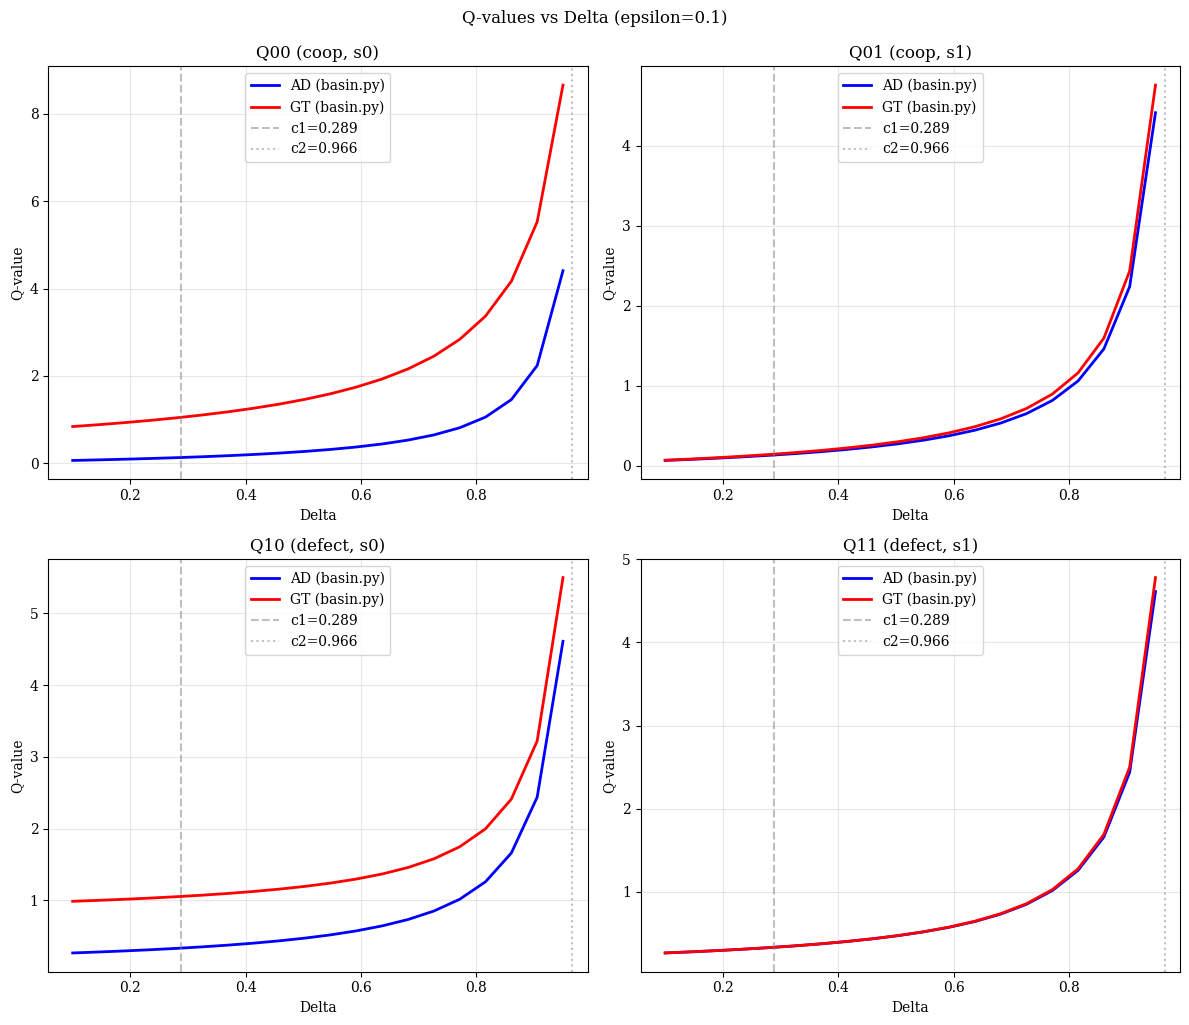

In [ ]:
# Sweep over delta values and compare Q-values
delta_values = np.linspace(0.1, 0.95, 20)

q_values_ad = []
q_values_gt = []

for d in delta_values:
    calc = Theoretical_QValueCalculator_Basin(
        epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=d
    )
    q_ad = calc.calculate_q_values_eAD()
    q_gt = calc.calculate_q_values_eGT()
    q_values_ad.append(q_ad)
    q_values_gt.append(q_gt)

q_values_ad = np.array(q_values_ad)
q_values_gt = np.array(q_values_gt)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

labels = ['Q00 (coop, s0)', 'Q01 (coop, s1)', 'Q10 (defect, s0)', 'Q11 (defect, s1)']

for i, (ax, label) in enumerate(zip(axes.flatten(), labels)):
    ax.plot(delta_values, q_values_ad[:, i], 'b-', label='AD (basin.py)', linewidth=2)
    ax.plot(delta_values, q_values_gt[:, i], 'r-', label='GT (basin.py)', linewidth=2)
    ax.axvline(x=c1, color='gray', linestyle='--', alpha=0.5, label=f'c1={c1:.3f}')
    ax.axvline(x=c2, color='gray', linestyle=':', alpha=0.5, label=f'c2={c2:.3f}')
    ax.set_xlabel('Delta')
    ax.set_ylabel('Q-value')
    ax.set_title(label)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle(f'Q-values vs Delta (epsilon={epsilon_value})', y=1.02)
plt.show()

## Direct Raw Q-values from basin.py

In [ ]:
# Show raw Q-values directly from basin.py functions
print("Raw Q-values from basin.py functions:")
print("="*60)

q_ad_raw = QvaluesADvsAD(T, R, P, S, epsilon_value, delta_value)
q_gt_raw = QvaluesGTvsGT(T, R, P, S, epsilon_value, delta_value)
q_ad_agt_raw = QvaluesADvsAGT(T, R, P, S, epsilon_value, delta_value)
q_ad_ac_raw = QvaluesADvsAC(T, R, P, S, epsilon_value, delta_value)

print(f"\nQvaluesADvsAD (AllD vs AllD):")
print(f"  State BC: Q_defect={q_ad_raw[0,0]:.4f}, Q_coop={q_ad_raw[0,1]:.4f}")
print(f"  State A1D: Q_defect={q_ad_raw[1,0]:.4f}, Q_coop={q_ad_raw[1,1]:.4f}")

print(f"\nQvaluesGTvsGT (GT vs GT):")
print(f"  State BC: Q_defect={q_gt_raw[0,0]:.4f}, Q_coop={q_gt_raw[0,1]:.4f}")
print(f"  State A1D: Q_defect={q_gt_raw[1,0]:.4f}, Q_coop={q_gt_raw[1,1]:.4f}")

print(f"\nQvaluesADvsAGT (AllD vs AGT):")
print(f"  State BC: Q_defect={q_ad_agt_raw[0,0]:.4f}, Q_coop={q_ad_agt_raw[0,1]:.4f}")
print(f"  State A1D: Q_defect={q_ad_agt_raw[1,0]:.4f}, Q_coop={q_ad_agt_raw[1,1]:.4f}")

print(f"\nQvaluesADvsAC (AllD vs AllC):")
print(f"  State BC: Q_defect={q_ad_ac_raw[0,0]:.4f}, Q_coop={q_ad_ac_raw[0,1]:.4f}")
print(f"  State A1D: Q_defect={q_ad_ac_raw[1,0]:.4f}, Q_coop={q_ad_ac_raw[1,1]:.4f}")

Raw Q-values from basin.py functions:

QvaluesADvsAD (AllD vs AllD):
  State BC: Q_defect=0.5850, Q_coop=0.3850
  State A1D: Q_defect=0.5850, Q_coop=0.3850

QvaluesGTvsGT (GT vs GT):
  State BC: Q_defect=1.3076, Q_coop=1.7768
  State A1D: Q_defect=0.5876, Q_coop=0.4229

QvaluesADvsAGT (AllD vs AGT):
  State BC: Q_defect=1.6350, Q_coop=1.4140
  State A1D: Q_defect=2.3550, Q_coop=1.7554

QvaluesADvsAC (AllD vs AllC):
  State BC: Q_defect=2.3850, Q_coop=2.1850
  State A1D: Q_defect=2.3850, Q_coop=2.1850
